# Topobathy GeoTIFF: GEBCO 2026 + the delivered mesh

North Carolina starts from a delivered SnapWave mesh (`inputs/delivery_2026-11-15/`,
built from a 3 arc-second DEM that was not delivered). This notebook:

1. traces the **AoI** from the mesh: its open boundary, closed over land;
2. cuts **GEBCO 2026** (local copy) around it;
3. writes the case raster: GEBCO with the **mesh depths on top** (3 arc-seconds),
   so the isobaths of notebook 03 are the ones the model sees.

The mesh is flattened at about 100 m offshore and its vertical datum is the DEM's
(not stated in the delivery): the raster inherits both inside the mesh.

In [1]:
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import rioxarray
import xarray as xr
from bluemath_tk.topo_bathy.mesh import mesh_to_raster, open_boundary_nodes, read_mesh
from shapely.geometry import Polygon
from utils.config import PATHS, SIMULATIONS, case_name, resolve

## Parameters

In [2]:
# Padding around the AoI bounds for the GEBCO subset
buffer_km = 50.0

# The AoI is traced from the mesh (next cell) and then read back
use_existing_aoi = True

# Points along the open boundary of the delivered mesh, in order (west lateral -> offshore -> north lateral)
boundary_points_file = resolve("inputs/delivery_2026-11-15/nc_mesh/nc_out/nc_bndpoints.txt")
# The closure over land is pushed this far out of the mesh box (deg)
aoi_land_margin = 0.05

# GEBCO 2026, local copy
gebco_url = "/lustre/geocean/DATA/GEBCO/GEBCO_2026/GEBCO_2026.nc"

In [3]:
# Inputs/outputs
input_aoi = resolve(PATHS["aoi_file"])
output_tiff = resolve(f"inputs/GEBCO/{case_name()}_GEBCO.tiff")

output_tiff.parent.mkdir(parents=True, exist_ok=True)

print(f"AoI shp  : {input_aoi}")
print(f"GeoTIFF  : {output_tiff}")
print(f"buffer km: {buffer_km}")

AoI shp  : /lustre/geocean/WORK/users/javiert/projects/HyGloW/NorthCarolina/inputs/AoI_Polygons/NorthCarolina_AoI.shp
GeoTIFF  : /lustre/geocean/WORK/users/javiert/projects/HyGloW/NorthCarolina/inputs/GEBCO/NorthCarolina_GEBCO.tiff
buffer km: 50.0


## AoI from the mesh

The AoI follows the mesh open boundary (where the goals go, notebook 04) and
closes over land, so the goal ring only keeps its sea side.

In [4]:
mesh = read_mesh(resolve(PATHS["mesh_file"]))
open_nodes = open_boundary_nodes(
    mesh, np.loadtxt(boundary_points_file), coast_depth=SIMULATIONS["snapwave"]["coast_depth"]
)
arc = np.column_stack([mesh.x[open_nodes], mesh.y[open_nodes]])
if arc[0, 1] > arc[-1, 1]:
    arc = arc[::-1]  # start at the south-west coast, end at the north coast
west, north = mesh.x.min() - aoi_land_margin, mesh.y.max() + aoi_land_margin
aoi_polygon = Polygon(
    [(west, arc[0, 1]), *arc, (arc[-1, 0], north), (west, north)]
).simplify(0.002)

input_aoi.parent.mkdir(parents=True, exist_ok=True)
gpd.GeoDataFrame({"name": ["aoi"]}, geometry=[aoi_polygon], crs="EPSG:4326").to_file(input_aoi)
print(f"open boundary: {len(open_nodes)} nodes; AoI: {len(aoi_polygon.exterior.coords)} vertices, valid {aoi_polygon.is_valid}")

INFO:pyogrio._io:Created 1 records


open boundary: 822 nodes; AoI: 194 vertices, valid True


## Build/Load AoI and derive buffered bounds

- If `use_existing_aoi=True`, read `paths.aoi_file`.
- If `use_existing_aoi=False`, create `paths.aoi_file` from `vertices_clockwise`.

Then expand outer bounds by 50 km (in projected meters) before subsetting GEBCO.

In [5]:
if use_existing_aoi:
    if not input_aoi.exists():
        raise FileNotFoundError(
            f"AoI file not found: {input_aoi}\n"
            "Set use_existing_aoi=False to create it from vertices_clockwise."
        )
    aoi_gdf = gpd.read_file(input_aoi).to_crs("EPSG:4326")
    print(f"Loaded existing AoI: {input_aoi}")
else:
    if len(vertices_clockwise) < 4:
        raise ValueError(
            "vertices_clockwise must contain at least 4 points (including closure)."
        )

    polygon = Polygon(vertices_clockwise)
    if not polygon.is_valid:
        raise ValueError("Provided vertices_clockwise do not form a valid polygon.")

    if not polygon.exterior.is_ccw:
        # As requested: vertices should be clockwise.
        pass
    else:
        print("Warning: vertices are counter-clockwise; proceeding anyway.")

    input_aoi.parent.mkdir(parents=True, exist_ok=True)
    aoi_gdf = gpd.GeoDataFrame({"name": ["aoi"]}, geometry=[polygon], crs="EPSG:4326")
    aoi_gdf.to_file(input_aoi)
    print(f"Created AoI shapefile: {input_aoi}")

# Buffer in meters using Web Mercator, then return to lon/lat.
buffered = aoi_gdf.to_crs("EPSG:3857").buffer(buffer_km * 1000.0).to_crs("EPSG:4326")

bbox = dict(zip(["lon_min", "lat_min", "lon_max", "lat_max"], buffered.total_bounds))
print({k: round(v, 5) for k, v in bbox.items()})
aoi_gdf

Loaded existing AoI: /lustre/geocean/WORK/users/javiert/projects/HyGloW/NorthCarolina/inputs/AoI_Polygons/NorthCarolina_AoI.shp
{'lon_min': -79.49666, 'lat_min': 32.72546, 'lon_max': -74.27857, 'lat_max': 37.10656}


,name,geometry
0,aoi,"POLYGON ((-79.0475 33.57378, -79.0475 36.7475,..."


## Download and subset GEBCO

In [6]:
GEBCO = xr.open_dataset(gebco_url)
GEBCO

<xarray.Dataset> Size: 7GB
Dimensions:    (lat: 43200, lon: 86400)
Coordinates:
  * lat        (lat) float64 346kB -90.0 -89.99 -89.99 ... 89.99 89.99 90.0
  * lon        (lon) float64 691kB -180.0 -180.0 -180.0 ... 180.0 180.0 180.0
Data variables:
    crs        |S1 1B ...
    elevation  (lat, lon) int16 7GB ...
Attributes: (12/36)
    title:                           The GEBCO_2026 Grid - a continuous terra...
    summary:                         The GEBCO_2026 Grid is a continuous, glo...
    keywords:                        BATHYMETRY/SEAFLOOR TOPOGRAPHY, DIGITAL ...
    Conventions:                     CF-1.6, ACDD-1.3
    id:                              DOI: 10.5285/4f68d5c7-45eb-f999-e063-708...
    naming_authority:                https://dx.doi.org
    ...                              ...
    geospatial_vertical_units:       meters
    geospatial_vertical_resolution:  1.0
    geospatial_vertical_positive:    up
    identifier_product_doi:          DOI: 10.5285/4f68d5c7-45eb-f999-e063-708...
    references:                      DOI: 10.5285/4f68d5c7-45eb-f999-e063-708...
    node_offset:                     1.0

In [7]:
elev_name = "elevation" if "elevation" in GEBCO else list(GEBCO.data_vars)[0]
print(f"elevation variable: {elev_name}")

# GEBCO latitude is usually descending — slice high to low
lat_slice = slice(bbox["lat_min"], bbox["lat_max"])
lon_slice = slice(bbox["lon_min"], bbox["lon_max"])

gebco_sel = GEBCO.sel(lon=lon_slice, lat=lat_slice).load()
gebco_sel

elevation variable: elevation


<xarray.Dataset> Size: 3MB
Dimensions:    (lat: 1052, lon: 1252)
Coordinates:
  * lat        (lat) float64 8kB 32.73 32.73 32.74 32.74 ... 37.1 37.1 37.11
  * lon        (lon) float64 10kB -79.49 -79.49 -79.49 ... -74.29 -74.29 -74.28
Data variables:
    crs        |S1 1B b''
    elevation  (lat, lon) int16 3MB -14 -15 -14 -15 ... -1839 -1848 -1857 -1868
Attributes: (12/36)
    title:                           The GEBCO_2026 Grid - a continuous terra...
    summary:                         The GEBCO_2026 Grid is a continuous, glo...
    keywords:                        BATHYMETRY/SEAFLOOR TOPOGRAPHY, DIGITAL ...
    Conventions:                     CF-1.6, ACDD-1.3
    id:                              DOI: 10.5285/4f68d5c7-45eb-f999-e063-708...
    naming_authority:                https://dx.doi.org
    ...                              ...
    geospatial_vertical_units:       meters
    geospatial_vertical_resolution:  1.0
    geospatial_vertical_positive:    up
    identifier_product_doi:          DOI: 10.5285/4f68d5c7-45eb-f999-e063-708...
    references:                      DOI: 10.5285/4f68d5c7-45eb-f999-e063-708...
    node_offset:                     1.0

## Write GeoTIFF (native GEBCO resolution)

In [8]:
gebco_raster = (
    gebco_sel[elev_name]
    .rio.set_spatial_dims(x_dim="lon", y_dim="lat", inplace=False)
    .rio.write_crs("EPSG:4326", inplace=False)
)

gebco_raster.rio.to_raster(output_tiff)
print(f"Wrote {output_tiff}")
print(f"CRS: {gebco_raster.rio.crs}")
print(f"Resolution (deg): {gebco_raster.rio.resolution()}")
print(f"Shape: {gebco_raster.shape}")

Wrote /lustre/geocean/WORK/users/javiert/projects/HyGloW/NorthCarolina/inputs/GEBCO/NorthCarolina_GEBCO.tiff
CRS: EPSG:4326
Resolution (deg): (0.004166666666666671, 0.004166666666666676)
Shape: (1052, 1252)


## Quick preview

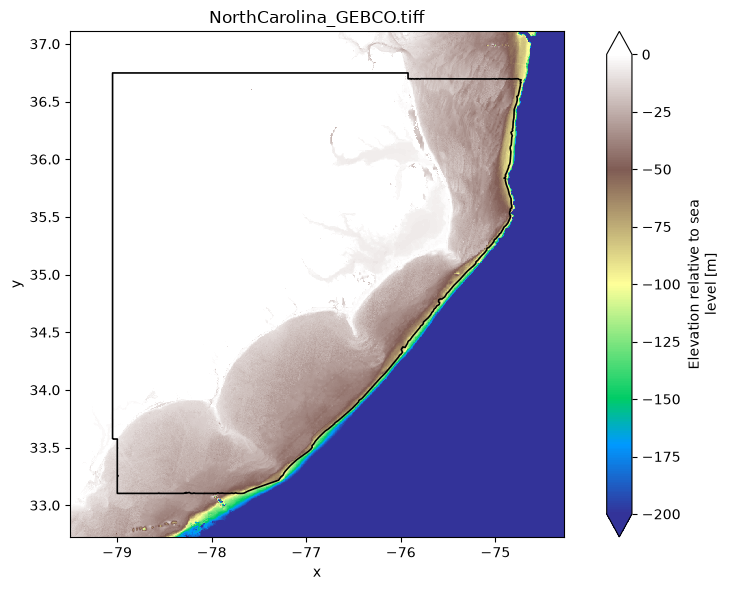

In [9]:
topobathy = rioxarray.open_rasterio(output_tiff).squeeze(drop=True)

fig, ax = plt.subplots(figsize=(9, 6))
topobathy.plot.imshow(ax=ax, vmin=-200, vmax=0, cmap="terrain")
aoi_gdf.boundary.plot(ax=ax, color="black", linewidth=1.2)
ax.set_title(output_tiff.name)
fig.tight_layout()
plt.show()

## Mesh depths on top of GEBCO

`bluemath_tk.topo_bathy.merge.merge_rasters` writes the sources on one lon/lat
grid in priority order (GEBCO at the bottom, the mesh on top, seam feathered
inside the mesh); a `_source.tiff` keeps which source wins each cell.
`paths.topobathy_file` points at this raster.

In [10]:
from bluemath_tk.topo_bathy.merge import RasterSource, merge_rasters, target_grid


def lonlat(da: xr.DataArray) -> xr.DataArray:
    """lon/lat raster -> x/y DataArray with its CRS."""
    da = da.rename({"lon": "x", "lat": "y"}).sortby("y", ascending=False)
    da.encoding.pop("grid_mapping", None)
    da.attrs.pop("grid_mapping", None)
    return da.rio.write_crs("EPSG:4326")


# --- merge parameters (lowest priority first) ---
merged_tiff = resolve(PATHS["topobathy_file"])
grid_step_deg = 3 / 3600  # 3 arc-seconds, the DEM the mesh was built from
merge_bounds = tuple(bbox[k] for k in ("lon_min", "lat_min", "lon_max", "lat_max"))
pad = 0.25
gebco_box = GEBCO[elev_name].sel(
    lon=slice(merge_bounds[0] - pad, merge_bounds[2] + pad),
    lat=slice(merge_bounds[1] - pad, merge_bounds[3] + pad),
).load()
mesh_raster = mesh_to_raster(mesh, resolution=grid_step_deg)
sources = [
    RasterSource("GEBCO 2026", lonlat(gebco_box.astype("float32"))),
    RasterSource("SnapWave mesh", lonlat(mesh_raster.astype("float32")), feather_m=1000),
]
print(f"merged : {merged_tiff}")
print(f"grid   : {grid_step_deg * 3600:g} arc-s over {merge_bounds}")

merged : /lustre/geocean/WORK/users/javiert/projects/HyGloW/NorthCarolina/inputs/Bathymetry/NorthCarolina_topobathy_3s.tiff
grid   : 3 arc-s over (-79.49665758422017, 32.72546272528442, -74.27857326776001, 37.106555854142435)


In [11]:
grid = target_grid(merge_bounds, grid_step_deg)
merged = merge_rasters(sources, grid)
merged_tiff.parent.mkdir(parents=True, exist_ok=True)
merged["elevation"].rio.to_raster(merged_tiff, compress="deflate", predictor=3, tiled=True)
merged["source"].rio.to_raster(merged_tiff.with_name(merged_tiff.stem + "_source.tiff"), compress="deflate", tiled=True)
print(f"Wrote {merged_tiff} {merged['elevation'].shape}")
{s.name: int((merged["source"] == i).sum()) for i, s in enumerate(sources)}

Wrote /lustre/geocean/WORK/users/javiert/projects/HyGloW/NorthCarolina/inputs/Bathymetry/NorthCarolina_topobathy_3s.tiff (5257, 6262)


{'GEBCO 2026': 26694902, 'SnapWave mesh': 6224432}

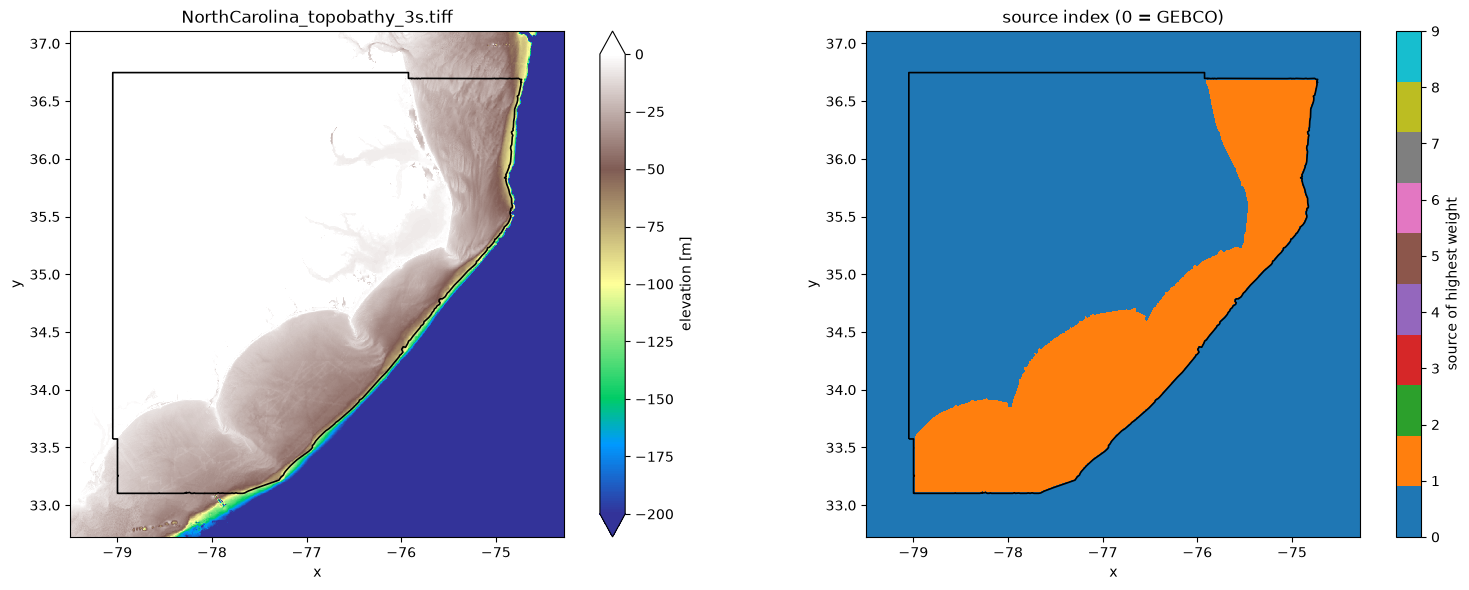

In [12]:
step = max(1, merged.sizes["x"] // 2000)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
merged["elevation"][::step, ::step].plot.imshow(ax=axes[0], vmin=-200, vmax=0, cmap="terrain")
merged["source"][::step, ::step].plot.imshow(ax=axes[1], cmap="tab10", vmin=0, vmax=9)
for ax in axes:
    aoi_gdf.boundary.plot(ax=ax, color="black", linewidth=1.2)
axes[0].set_title(merged_tiff.name)
axes[1].set_title("source index (0 = GEBCO)")
fig.tight_layout()
plt.show()

## Next step

`02_Create_mesh_by_bluemesh2d.ipynb` checks the delivered mesh; `03` builds the
observations and the output sites.